In [1]:
##import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

Gnerating a random dataset with outliars

Text(0, 0.5, 'Y dataset')

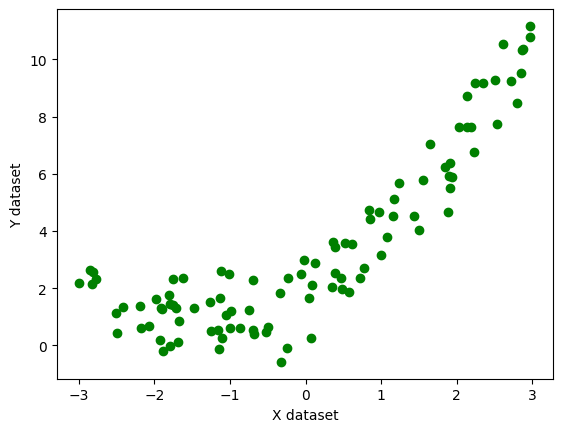

In [2]:
X = 6 * np.random.rand(100, 1) - 3
y =0.5 * X**2 + 1.5*X + 2 + np.random.randn(100, 1)
# quadratic equation used- y=0.5x^2+1.5x+2+outliers
plt.scatter(X,y,color='g')
plt.xlabel('X dataset')
plt.ylabel('Y dataset')

Implimenting simple LR first

In [3]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [4]:
## Lets implement Simple Linear Regression
from sklearn.linear_model import LinearRegression
regression_1=LinearRegression()

In [5]:
regression_1.fit(X_train,y_train)

LinearRegression()

In [6]:
from sklearn.metrics import r2_score
score=r2_score(y_test,regression_1.predict(X_test))
print(score)

0.6674802930293818


Text(0, 0.5, 'Y')

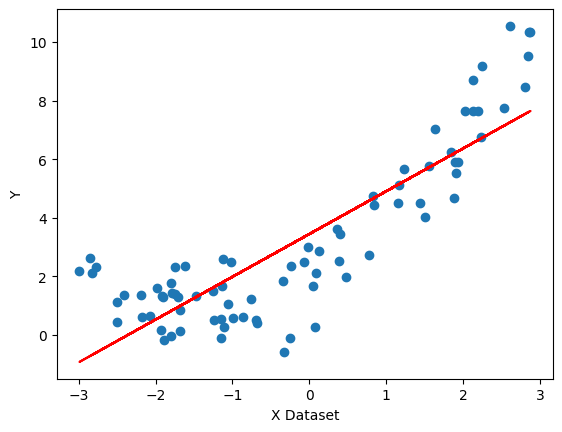

In [7]:
## Lets visualize this model
plt.plot(X_train,regression_1.predict(X_train),color='r')
plt.scatter(X_train,y_train)
plt.xlabel("X Dataset")
plt.ylabel("Y")

Applying Polynomial Features

In [8]:
#LEts apply polynomial transformation
from sklearn.preprocessing import PolynomialFeatures

In [44]:
poly=PolynomialFeatures(degree=2, include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [45]:
X_train_poly

array([[ 1.00000000e+00, -3.38513306e-01,  1.14591258e-01],
       [ 1.00000000e+00, -2.82113398e+00,  7.95879691e+00],
       [ 1.00000000e+00,  1.64148646e+00,  2.69447781e+00],
       [ 1.00000000e+00,  2.84805906e+00,  8.11144042e+00],
       [ 1.00000000e+00, -1.75052604e+00,  3.06434142e+00],
       [ 1.00000000e+00, -8.67328414e-01,  7.52258578e-01],
       [ 1.00000000e+00,  2.02685312e+00,  4.10813357e+00],
       [ 1.00000000e+00, -6.40037756e-02,  4.09648329e-03],
       [ 1.00000000e+00,  8.18704932e-02,  6.70277765e-03],
       [ 1.00000000e+00,  2.53597995e+00,  6.43119432e+00],
       [ 1.00000000e+00,  3.93275045e-01,  1.54665261e-01],
       [ 1.00000000e+00,  2.24414863e+00,  5.03620307e+00],
       [ 1.00000000e+00,  3.63475316e-01,  1.32114306e-01],
       [ 1.00000000e+00, -2.50568961e+00,  6.27848043e+00],
       [ 1.00000000e+00,  7.72262281e-01,  5.96389031e-01],
       [ 1.00000000e+00,  1.27018881e-01,  1.61337961e-02],
       [ 1.00000000e+00,  4.75876142e-01

In [46]:
X_test_poly

array([[ 1.        ,  1.07883535,  1.16388572],
       [ 1.        , -0.99051589,  0.98112173],
       [ 1.        ,  0.46792908,  0.21895762],
       [ 1.        ,  0.97648269,  0.95351845],
       [ 1.        ,  2.97271597,  8.83704026],
       [ 1.        ,  2.50309907,  6.26550494],
       [ 1.        ,  0.99356179,  0.98716504],
       [ 1.        , -2.81612956,  7.93058568],
       [ 1.        ,  0.51773291,  0.26804737],
       [ 1.        ,  0.56901647,  0.32377974],
       [ 1.        ,  2.35051318,  5.52491223],
       [ 1.        ,  1.90761406,  3.63899142],
       [ 1.        ,  2.71883577,  7.39206794],
       [ 1.        , -0.50068909,  0.25068957],
       [ 1.        ,  0.35581321,  0.12660304],
       [ 1.        ,  0.72083882,  0.5196086 ],
       [ 1.        , -0.69032307,  0.47654594],
       [ 1.        ,  2.96703172,  8.80327723],
       [ 1.        ,  0.6166544 ,  0.38026264],
       [ 1.        , -0.52723622,  0.27797803]])

Predicting on the updated Polynomial Features Data

In [47]:

from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.958447775003019


In [48]:
print(regression.coef_)

[[0.         1.43125464 0.49368666]]


In [49]:
print(regression.intercept_)

[1.98650443]


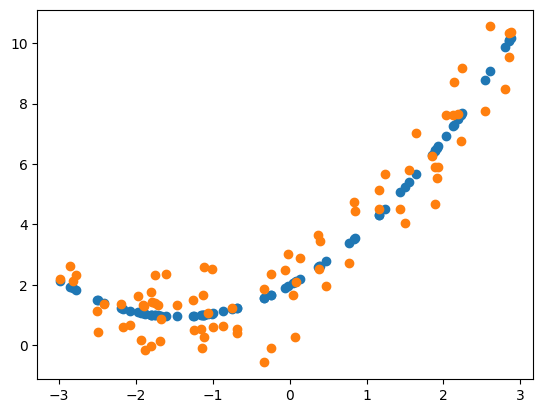

In [50]:
plt.scatter(X_train,regression.predict(X_train_poly))
plt.scatter(X_train,y_train)

In [53]:
poly=PolynomialFeatures(degree=7,include_bias=True)
X_train_poly=poly.fit_transform(X_train)
X_test_poly=poly.transform(X_test)

In [54]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score=r2_score(y_test,y_pred)
print(score)

0.9439848976936659


In [55]:
#3 Prediction of new data set
X_new = np.linspace(-3, 3, 200).reshape(200, 1)
X_new_poly = poly.transform(X_new)
X_new_poly

array([[ 1.00000000e+00, -3.00000000e+00,  9.00000000e+00, ...,
        -2.43000000e+02,  7.29000000e+02, -2.18700000e+03],
       [ 1.00000000e+00, -2.96984925e+00,  8.82000455e+00, ...,
        -2.31031939e+02,  6.86130029e+02, -2.03770275e+03],
       [ 1.00000000e+00, -2.93969849e+00,  8.64182723e+00, ...,
        -2.19540146e+02,  6.45381836e+02, -1.89722801e+03],
       ...,
       [ 1.00000000e+00,  2.93969849e+00,  8.64182723e+00, ...,
         2.19540146e+02,  6.45381836e+02,  1.89722801e+03],
       [ 1.00000000e+00,  2.96984925e+00,  8.82000455e+00, ...,
         2.31031939e+02,  6.86130029e+02,  2.03770275e+03],
       [ 1.00000000e+00,  3.00000000e+00,  9.00000000e+00, ...,
         2.43000000e+02,  7.29000000e+02,  2.18700000e+03]],
      shape=(200, 8))

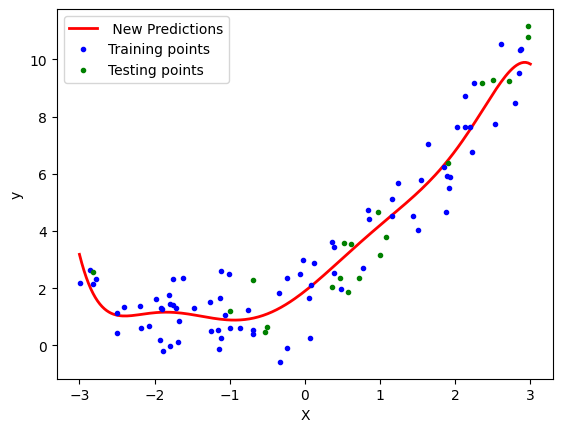

In [56]:
y_new = regression.predict(X_new_poly)
plt.plot(X_new, y_new, "r-", linewidth=2, label=" New Predictions")
plt.plot(X_train, y_train, "b.",label='Training points')
plt.plot(X_test, y_test, "g.",label='Testing points')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.show()

**Pipeline Concept**

In [57]:
from sklearn.pipeline import Pipeline

In [59]:
def poly_regression(degree):
    X_new = np.linspace(-3, 3, 200).reshape(200, 1)

    poly_features=PolynomialFeatures(degree=degree,include_bias=True)
    lin_reg=LinearRegression()
    poly_regression=Pipeline([
        ("poly_features",poly_features),
        ("lin_reg",lin_reg)
    ])
    poly_regression.fit(X_train,y_train) ## ploynomial and fit of linear reression
    y_pred_new=poly_regression.predict(X_new)
    #plotting prediction line
    plt.plot(X_new, y_pred_new,'r', label="Degree " + str(degree), linewidth=2)
    plt.plot(X_train, y_train, "b.", linewidth=3)
    plt.plot(X_test, y_test, "g.", linewidth=3)
    plt.legend(loc="upper left")
    plt.xlabel("X")
    plt.ylabel("y")
    plt.axis([-4,4, 0, 10])
    plt.show()


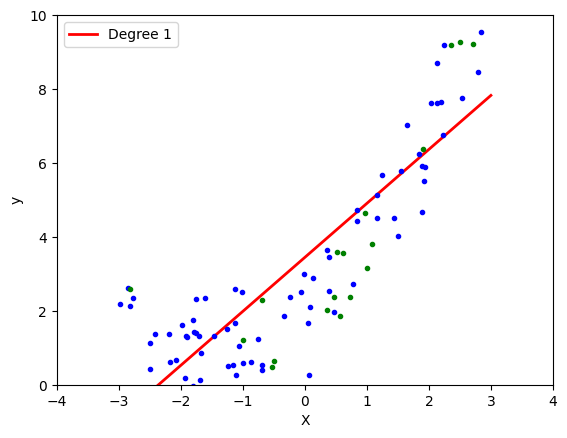

In [60]:
poly_regression(1)

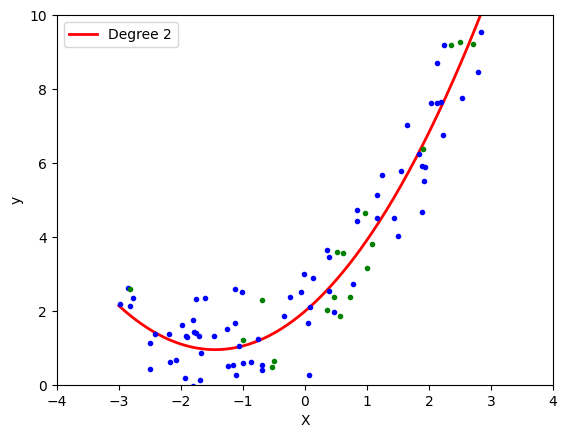

In [61]:
poly_regression(2)

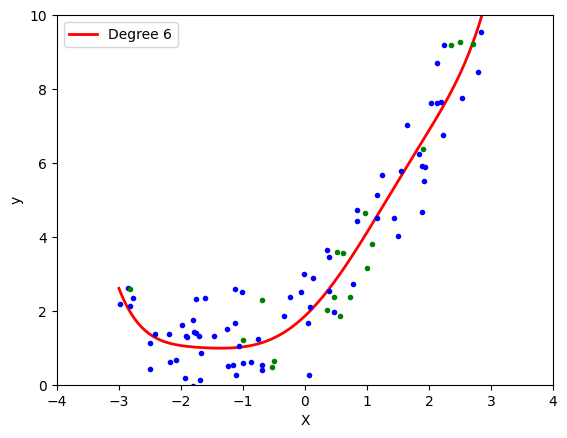

In [65]:
poly_regression(6)

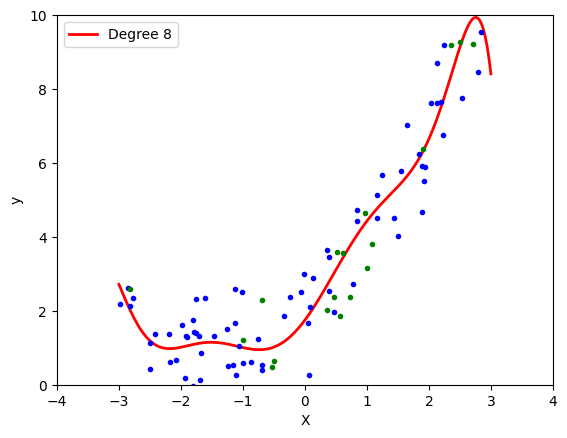

In [66]:
poly_regression(8)